<a href="https://colab.research.google.com/github/rontalapoojareddy/M.T-Project/blob/main/MTech_XAI_Intrusion_Detection.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
# ============================================================
# M.TECH CSE PROJECT
# Explainable AI-Based Intelligent Network Intrusion
# Detection System Using Machine Learning and Deep Learning
# ============================================================

PROJECT_NAME = "Explainable AI-Based Intelligent Network Intrusion Detection System"

print("=" * 70)
print("M.TECH CSE PROJECT")
print(PROJECT_NAME)
print("=" * 70)
print("Google Colab environment initialized successfully!")

M.TECH CSE PROJECT
Explainable AI-Based Intelligent Network Intrusion Detection System
Google Colab environment initialized successfully!


**Step-1 Importing Libraries**

In [2]:
!pip -q install shap xgboost imbalanced-learn

In [3]:
import warnings
warnings.filterwarnings("ignore")

import os
import numpy as np
import pandas as pd

import matplotlib.pyplot as plt

# Machine Learning
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.impute import SimpleImputer

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    roc_auc_score,
    roc_curve
)

# XGBoost
from xgboost import XGBClassifier

# Deep Learning
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

# Explainable AI
import shap

print("All libraries imported successfully!")

print("\nVersions:")
print("Python/Pandas :", pd.__version__)
print("TensorFlow    :", tf.__version__)
print("SHAP          :", shap.__version__)

All libraries imported successfully!

Versions:
Python/Pandas : 2.2.3
TensorFlow    : 2.21.0
SHAP          : 0.54.1


In [4]:
import random

RANDOM_STATE = 42

random.seed(RANDOM_STATE)
np.random.seed(RANDOM_STATE)
tf.random.set_seed(RANDOM_STATE)

print("Random seed set to:", RANDOM_STATE)

Random seed set to: 42


**Step-2 Downloading_Data**

In [10]:
import os
import requests

DATA_DIR = "/content/unsw_nb15"
os.makedirs(DATA_DIR, exist_ok=True)

BASE_URL = (
    "https://raw.githubusercontent.com/Nir-J/ML-Projects/"
    "master/UNSW-Network_Packet_Classification/"
)

train_url = BASE_URL + "UNSW_NB15_training-set.csv"
test_url  = BASE_URL + "UNSW_NB15_testing-set.csv"

train_path = os.path.join(DATA_DIR, "UNSW_NB15_training-set.csv")
test_path  = os.path.join(DATA_DIR, "UNSW_NB15_testing-set.csv")


def download_file(url, path):
    print("Downloading:", os.path.basename(path))

    response = requests.get(url, timeout=120)
    response.raise_for_status()

    with open(path, "wb") as f:
        f.write(response.content)

    size_mb = os.path.getsize(path) / (1024 * 1024)

    print("Download successful!")
    print(f"File size: {size_mb:.2f} MB")


try:
    print("=" * 60)
    print("DOWNLOADING UNSW-NB15 DATASET")
    print("=" * 60)

    download_file(train_url, train_path)

    print()

    download_file(test_url, test_path)

    print("\n" + "=" * 60)
    print("DOWNLOAD COMPLETED SUCCESSFULLY")
    print("=" * 60)

    print("Training file exists:", os.path.exists(train_path))
    print("Testing file exists :", os.path.exists(test_path))

except Exception as e:
    print("\nDOWNLOAD FAILED")
    print("Error:", e)

DOWNLOADING UNSW-NB15 DATASET
Downloading: UNSW_NB15_training-set.csv
Download successful!
File size: 30.80 MB

Downloading: UNSW_NB15_testing-set.csv
Download successful!
File size: 14.67 MB

DOWNLOAD COMPLETED SUCCESSFULLY
Training file exists: True
Testing file exists : True


In [11]:
train_df = pd.read_csv(train_path)
test_df = pd.read_csv(test_path)

print("=" * 60)
print("DATASET LOADED SUCCESSFULLY")
print("=" * 60)

print("\nTraining dataset shape:")
print(train_df.shape)

print("\nTesting dataset shape:")
print(test_df.shape)

print("\nTotal records:")
print(len(train_df) + len(test_df))

print("\nNumber of columns:")
print(len(train_df.columns))

print("\nFirst 5 columns:")
print(train_df.columns[:5].tolist())

print("\nLast 5 columns:")
print(train_df.columns[-5:].tolist())

DATASET LOADED SUCCESSFULLY

Training dataset shape:
(175341, 45)

Testing dataset shape:
(82332, 45)

Total records:
257673

Number of columns:
45

First 5 columns:
['id', 'dur', 'proto', 'service', 'state']

Last 5 columns:
['ct_src_ltm', 'ct_srv_dst', 'is_sm_ips_ports', 'attack_cat', 'label']


**Step-3  Pre_Processing**

In [12]:
print("=" * 80)
print("UNSW-NB15 DATASET — BASIC INSPECTION")
print("=" * 80)

# Display first 5 rows
print("\nFIRST 5 ROWS:")
display(train_df.head())

# Column names
print("\n" + "=" * 80)
print("ALL COLUMNS")
print("=" * 80)

for i, col in enumerate(train_df.columns, 1):
    print(f"{i:2}. {col}")

# Data types
print("\n" + "=" * 80)
print("DATA TYPES")
print("=" * 80)

print(train_df.dtypes.value_counts())

# Missing values
print("\n" + "=" * 80)
print("MISSING VALUES")
print("=" * 80)

missing = train_df.isnull().sum()
missing = missing[missing > 0].sort_values(ascending=False)

if len(missing) == 0:
    print("No missing values found.")
else:
    print(missing)

# Duplicate rows
print("\n" + "=" * 80)
print("DUPLICATE ROWS")
print("=" * 80)

print("Number of duplicate rows:", train_df.duplicated().sum())

UNSW-NB15 DATASET — BASIC INSPECTION

FIRST 5 ROWS:


,id,dur,proto,service,state,spkts,dpkts,sbytes,dbytes,rate,...,ct_dst_sport_ltm,ct_dst_src_ltm,is_ftp_login,ct_ftp_cmd,ct_flw_http_mthd,ct_src_ltm,ct_srv_dst,is_sm_ips_ports,attack_cat,label
0,1,0.121478,tcp,-,FIN,6,4,258,172,74.087490,...,1,1,0,0,0,1,1,0,Normal,0
1,2,0.649902,tcp,-,FIN,14,38,734,42014,78.473372,...,1,2,0,0,0,1,6,0,Normal,0
2,3,1.623129,tcp,-,FIN,8,16,364,13186,14.170161,...,1,3,0,0,0,2,6,0,Normal,0
3,4,1.681642,tcp,ftp,FIN,12,12,628,770,13.677108,...,1,3,1,1,0,2,1,0,Normal,0
4,5,0.449454,tcp,-,FIN,10,6,534,268,33.373826,...,1,40,0,0,0,2,39,0,Normal,0



ALL COLUMNS
 1. id
 2. dur
 3. proto
 4. service
 5. state
 6. spkts
 7. dpkts
 8. sbytes
 9. dbytes
10. rate
11. sttl
12. dttl
13. sload
14. dload
15. sloss
16. dloss
17. sinpkt
18. dinpkt
19. sjit
20. djit
21. swin
22. stcpb
23. dtcpb
24. dwin
25. tcprtt
26. synack
27. ackdat
28. smean
29. dmean
30. trans_depth
31. response_body_len
32. ct_srv_src
33. ct_state_ttl
34. ct_dst_ltm
35. ct_src_dport_ltm
36. ct_dst_sport_ltm
37. ct_dst_src_ltm
38. is_ftp_login
39. ct_ftp_cmd
40. ct_flw_http_mthd
41. ct_src_ltm
42. ct_srv_dst
43. is_sm_ips_ports
44. attack_cat
45. label

DATA TYPES
int64      30
float64    11
object      4
Name: count, dtype: int64

MISSING VALUES
No missing values found.

DUPLICATE ROWS
Number of duplicate rows: 0


**Analysing Data**

BINARY TARGET ANALYSIS

Label counts:
label
0     56000
1    119341
Name: count, dtype: int64

Label percentages:
0 (Normal): 31.94%
1 (Attack): 68.06%


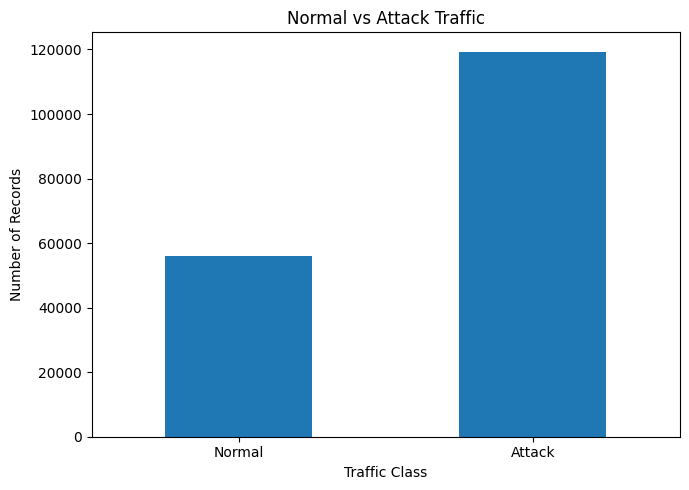

In [13]:
print("=" * 80)
print("BINARY TARGET ANALYSIS")
print("=" * 80)

label_counts = train_df["label"].value_counts().sort_index()
label_percent = (
    train_df["label"]
    .value_counts(normalize=True)
    .sort_index()
    .mul(100)
)

print("\nLabel counts:")
print(label_counts)

print("\nLabel percentages:")

for label, percentage in label_percent.items():
    name = "Normal" if label == 0 else "Attack"
    print(f"{label} ({name}): {percentage:.2f}%")

# Plot
plt.figure(figsize=(7, 5))

label_counts.rename(
    index={0: "Normal", 1: "Attack"}
).plot(kind="bar")

plt.title("Normal vs Attack Traffic")
plt.xlabel("Traffic Class")
plt.ylabel("Number of Records")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

Cell 9 Attack

ATTACK CATEGORY ANALYSIS

Attack category counts:
attack_cat
Normal            56000
Generic           40000
Exploits          33393
Fuzzers           18184
DoS               12264
Reconnaissance    10491
Analysis           2000
Backdoor           1746
Shellcode          1133
Worms               130
Name: count, dtype: int64

ATTACK CATEGORY PERCENTAGES
attack_cat
Normal            31.94
Generic           22.81
Exploits          19.04
Fuzzers           10.37
DoS                6.99
Reconnaissance     5.98
Analysis           1.14
Backdoor           1.00
Shellcode          0.65
Worms              0.07
Name: proportion, dtype: float64

Total unique categories: 10


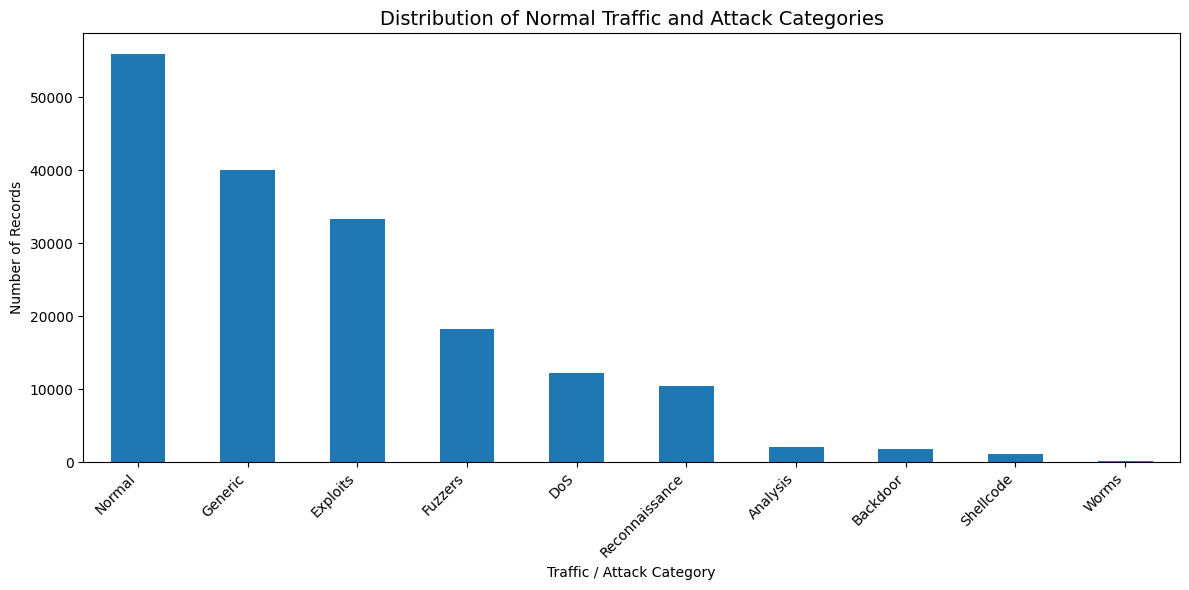

In [14]:
# ============================================================
# CELL 9 — ATTACK CATEGORY ANALYSIS
# ============================================================

print("=" * 80)
print("ATTACK CATEGORY ANALYSIS")
print("=" * 80)

# Count each attack category
attack_counts = train_df["attack_cat"].value_counts()

print("\nAttack category counts:")
print(attack_counts)

print("\n" + "=" * 80)
print("ATTACK CATEGORY PERCENTAGES")
print("=" * 80)

attack_percentages = (
    train_df["attack_cat"]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)

print(attack_percentages)

print("\nTotal unique categories:",
      train_df["attack_cat"].nunique())


# ============================================================
# GRAPH
# ============================================================

plt.figure(figsize=(12, 6))

attack_counts.plot(kind="bar")

plt.title(
    "Distribution of Normal Traffic and Attack Categories",
    fontsize=14
)

plt.xlabel("Traffic / Attack Category")
plt.ylabel("Number of Records")

plt.xticks(rotation=45, ha="right")

plt.tight_layout()
plt.show()

Features

In [15]:
# ============================================================
# CELL 10 — FEATURE TYPE ANALYSIS
# ============================================================

print("=" * 80)
print("FEATURE TYPE ANALYSIS")
print("=" * 80)

# Identify categorical columns
categorical_cols = train_df.select_dtypes(
    include=["object", "category"]
).columns.tolist()

# Identify numerical columns
numerical_cols = train_df.select_dtypes(
    include=[np.number]
).columns.tolist()


print("\nCATEGORICAL COLUMNS:")
print(categorical_cols)

print("\nNumber of categorical columns:")
print(len(categorical_cols))


print("\n" + "=" * 80)

print("\nNUMERICAL COLUMNS:")
print(numerical_cols)

print("\nNumber of numerical columns:")
print(len(numerical_cols))


# ============================================================
# UNIQUE VALUES IN CATEGORICAL COLUMNS
# ============================================================

print("\n" + "=" * 80)
print("UNIQUE VALUES IN CATEGORICAL COLUMNS")
print("=" * 80)

for col in categorical_cols:

    print(f"\nColumn: {col}")

    print("Number of unique values:",
          train_df[col].nunique())

    # Show first 20 unique values
    print("Sample values:")
    print(train_df[col].unique()[:20])

FEATURE TYPE ANALYSIS

CATEGORICAL COLUMNS:
['proto', 'service', 'state', 'attack_cat']

Number of categorical columns:
4


NUMERICAL COLUMNS:
['id', 'dur', 'spkts', 'dpkts', 'sbytes', 'dbytes', 'rate', 'sttl', 'dttl', 'sload', 'dload', 'sloss', 'dloss', 'sinpkt', 'dinpkt', 'sjit', 'djit', 'swin', 'stcpb', 'dtcpb', 'dwin', 'tcprtt', 'synack', 'ackdat', 'smean', 'dmean', 'trans_depth', 'response_body_len', 'ct_srv_src', 'ct_state_ttl', 'ct_dst_ltm', 'ct_src_dport_ltm', 'ct_dst_sport_ltm', 'ct_dst_src_ltm', 'is_ftp_login', 'ct_ftp_cmd', 'ct_flw_http_mthd', 'ct_src_ltm', 'ct_srv_dst', 'is_sm_ips_ports', 'label']

Number of numerical columns:
41

UNIQUE VALUES IN CATEGORICAL COLUMNS

Column: proto
Number of unique values: 133
Sample values:
['tcp' 'udp' 'arp' 'ospf' 'icmp' 'igmp' 'rtp' 'ddp' 'ipv6-frag' 'cftp'
 'wsn' 'pvp' 'wb-expak' 'mtp' 'pri-enc' 'sat-mon' 'cphb' 'sun-nd' 'iso-ip'
 'xtp']

Column: service
Number of unique values: 13
Sample values:
['-' 'ftp' 'smtp' 'snmp' 'http' 'ftp-da

**Step 4 — Prepare Binary Intrusion Detection Data**

In [16]:
# ============================================================
# CELL 11 — PREPARE BINARY CLASSIFICATION DATA
# ============================================================

print("=" * 80)
print("PREPARING BINARY INTRUSION DETECTION DATA")
print("=" * 80)

# ------------------------------------------------------------
# Columns that must NOT be used as input features
# ------------------------------------------------------------

DROP_COLUMNS = ["id", "attack_cat"]

TARGET_COLUMN = "label"


# ------------------------------------------------------------
# Separate training data
# ------------------------------------------------------------

X_train_raw = train_df.drop(
    columns=DROP_COLUMNS + [TARGET_COLUMN]
)

y_train = train_df[TARGET_COLUMN].copy()


# ------------------------------------------------------------
# Separate testing data
# ------------------------------------------------------------

X_test_raw = test_df.drop(
    columns=DROP_COLUMNS + [TARGET_COLUMN]
)

y_test = test_df[TARGET_COLUMN].copy()


# ------------------------------------------------------------
# Display information
# ------------------------------------------------------------

print("\nOriginal training shape:")
print(train_df.shape)

print("\nInput training shape:")
print(X_train_raw.shape)

print("\nTraining target shape:")
print(y_train.shape)

print("\nInput testing shape:")
print(X_test_raw.shape)

print("\nTesting target shape:")
print(y_test.shape)


print("\n" + "=" * 80)
print("LEAKAGE CHECK")
print("=" * 80)

print("id present in features:",
      "id" in X_train_raw.columns)

print("attack_cat present in features:",
      "attack_cat" in X_train_raw.columns)

print("label present in features:",
      "label" in X_train_raw.columns)


print("\nNumber of model input features:",
      X_train_raw.shape[1])

PREPARING BINARY INTRUSION DETECTION DATA

Original training shape:
(175341, 45)

Input training shape:
(175341, 42)

Training target shape:
(175341,)

Input testing shape:
(82332, 42)

Testing target shape:
(82332,)

LEAKAGE CHECK
id present in features: False
attack_cat present in features: False
label present in features: False

Number of model input features: 42


In [17]:
# ============================================================
# CELL 12 — IDENTIFY MODEL FEATURE TYPES
# ============================================================

binary_categorical_features = (
    X_train_raw
    .select_dtypes(include=["object", "category"])
    .columns
    .tolist()
)

binary_numerical_features = (
    X_train_raw
    .select_dtypes(include=[np.number])
    .columns
    .tolist()
)


print("=" * 80)
print("BINARY MODEL FEATURE TYPES")
print("=" * 80)

print("\nCategorical input features:")
print(binary_categorical_features)

print("\nNumber of categorical features:",
      len(binary_categorical_features))

print("\nNumber of numerical features:",
      len(binary_numerical_features))

print("\nTotal:")
print(
    len(binary_categorical_features)
    + len(binary_numerical_features)
)

BINARY MODEL FEATURE TYPES

Categorical input features:
['proto', 'service', 'state']

Number of categorical features: 3

Number of numerical features: 39

Total:
42


In [18]:
# ============================================================
# CELL 13 — CHECK CATEGORICAL DIFFERENCES
# ============================================================

print("=" * 80)
print("TRAIN VS TEST CATEGORY CHECK")
print("=" * 80)

for col in binary_categorical_features:

    train_values = set(
        X_train_raw[col].astype(str).unique()
    )

    test_values = set(
        X_test_raw[col].astype(str).unique()
    )

    unseen_in_test = test_values - train_values

    print(f"\nFeature: {col}")

    print("Training categories:",
          len(train_values))

    print("Testing categories:",
          len(test_values))

    print("Categories present in test but not train:",
          len(unseen_in_test))

    if unseen_in_test:
        print("Unseen values:",
              sorted(unseen_in_test))

TRAIN VS TEST CATEGORY CHECK

Feature: proto
Training categories: 133
Testing categories: 131
Categories present in test but not train: 0

Feature: service
Training categories: 13
Testing categories: 13
Categories present in test but not train: 0

Feature: state
Training categories: 9
Testing categories: 7
Categories present in test but not train: 2
Unseen values: ['ACC', 'CLO']


In [19]:
# ============================================================
# CELL 14 — CREATE PREPROCESSING PIPELINE
# ============================================================

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer


# ------------------------------------------------------------
# Numerical preprocessing
# ------------------------------------------------------------

numerical_pipeline = Pipeline(
    steps=[
        (
            "imputer",
            SimpleImputer(strategy="median")
        ),
        (
            "scaler",
            StandardScaler()
        )
    ]
)


# ------------------------------------------------------------
# Categorical preprocessing
# ------------------------------------------------------------

categorical_pipeline = Pipeline(
    steps=[
        (
            "imputer",
            SimpleImputer(strategy="most_frequent")
        ),
        (
            "onehot",
            OneHotEncoder(
                handle_unknown="ignore",
                sparse_output=True
            )
        )
    ]
)


# ------------------------------------------------------------
# Combine both
# ------------------------------------------------------------

preprocessor = ColumnTransformer(
    transformers=[
        (
            "numerical",
            numerical_pipeline,
            binary_numerical_features
        ),
        (
            "categorical",
            categorical_pipeline,
            binary_categorical_features
        )
    ]
)


print("=" * 80)
print("PREPROCESSING PIPELINE CREATED")
print("=" * 80)

print("\nNumerical features:",
      len(binary_numerical_features))

print("Categorical features:",
      len(binary_categorical_features))

print("\nPipeline ready!")

PREPROCESSING PIPELINE CREATED

Numerical features: 39
Categorical features: 3

Pipeline ready!


In [20]:
# ============================================================
# CELL 15 — FIT AND TRANSFORM DATA
# ============================================================

print("Fitting preprocessing pipeline...")

# IMPORTANT:
# Learn preprocessing parameters ONLY from training data
X_train_processed = preprocessor.fit_transform(
    X_train_raw
)

# Test data is only transformed
X_test_processed = preprocessor.transform(
    X_test_raw
)


print("\n" + "=" * 80)
print("PREPROCESSING COMPLETED")
print("=" * 80)

print("\nBefore preprocessing:")

print("Training:",
      X_train_raw.shape)

print("Testing :",
      X_test_raw.shape)


print("\nAfter preprocessing:")

print("Training:",
      X_train_processed.shape)

print("Testing :",
      X_test_processed.shape)


print("\nNaN check:")

if hasattr(X_train_processed, "data"):
    print(
        "Training NaN:",
        np.isnan(X_train_processed.data).sum()
    )

    print(
        "Testing NaN:",
        np.isnan(X_test_processed.data).sum()
    )

else:
    print(
        "Training NaN:",
        np.isnan(X_train_processed).sum()
    )

    print(
        "Testing NaN:",
        np.isnan(X_test_processed).sum()
    )

Fitting preprocessing pipeline...

PREPROCESSING COMPLETED

Before preprocessing:
Training: (175341, 42)
Testing : (82332, 42)

After preprocessing:
Training: (175341, 194)
Testing : (82332, 194)

NaN check:
Training NaN: 0
Testing NaN: 0


**Step 5 — Model 1: Logistic Regression**

In [21]:
# ============================================================
# CELL 16 — LOGISTIC REGRESSION BASELINE MODEL
# ============================================================

import time

print("=" * 80)
print("MODEL 1 — LOGISTIC REGRESSION")
print("=" * 80)

logistic_model = LogisticRegression(
    max_iter=1000,
    class_weight="balanced",
    random_state=RANDOM_STATE,
    solver="liblinear"
)

start_time = time.time()

print("\nTraining Logistic Regression...")

logistic_model.fit(
    X_train_processed,
    y_train
)

training_time = time.time() - start_time

print("\nTraining completed successfully!")

print(
    f"Training time: {training_time:.2f} seconds"
)

MODEL 1 — LOGISTIC REGRESSION

Training Logistic Regression...

Training completed successfully!
Training time: 22.01 seconds


In [22]:
# ============================================================
# CELL 17 — LOGISTIC REGRESSION PREDICTIONS
# ============================================================

print("=" * 80)
print("GENERATING PREDICTIONS")
print("=" * 80)

# Predicted classes
logistic_predictions = logistic_model.predict(
    X_test_processed
)

# Probability of ATTACK class
logistic_probabilities = logistic_model.predict_proba(
    X_test_processed
)[:, 1]


print("\nPredictions completed!")

print("\nNumber of predictions:",
      len(logistic_predictions))

print("\nFirst 20 predicted classes:")
print(logistic_predictions[:20])

print("\nFirst 10 attack probabilities:")
print(
    np.round(
        logistic_probabilities[:10],
        4
    )
)

GENERATING PREDICTIONS

Predictions completed!

Number of predictions: 82332

First 20 predicted classes:
[1 1 1 1 1 1 1 1 0 0 0 0 1 1 1 1 1 1 1 1]

First 10 attack probabilities:
[0.7727 0.7479 0.7376 0.7791 0.7384 0.825  0.8027 0.6923 0.     0.    ]


In [23]:
# ============================================================
# CELL 18 — LOGISTIC REGRESSION EVALUATION
# ============================================================

log_accuracy = accuracy_score(
    y_test,
    logistic_predictions
)

log_precision = precision_score(
    y_test,
    logistic_predictions
)

log_recall = recall_score(
    y_test,
    logistic_predictions
)

log_f1 = f1_score(
    y_test,
    logistic_predictions
)

log_auc = roc_auc_score(
    y_test,
    logistic_probabilities
)


print("=" * 80)
print("LOGISTIC REGRESSION — TEST RESULTS")
print("=" * 80)

print(f"\nAccuracy  : {log_accuracy:.4f} ({log_accuracy*100:.2f}%)")
print(f"Precision : {log_precision:.4f} ({log_precision*100:.2f}%)")
print(f"Recall    : {log_recall:.4f} ({log_recall*100:.2f}%)")
print(f"F1 Score  : {log_f1:.4f} ({log_f1*100:.2f}%)")
print(f"ROC-AUC   : {log_auc:.4f}")

print("\n" + "=" * 80)
print("CLASSIFICATION REPORT")
print("=" * 80)

print(
    classification_report(
        y_test,
        logistic_predictions,
        target_names=[
            "Normal",
            "Attack"
        ],
        digits=4
    )
)

LOGISTIC REGRESSION — TEST RESULTS

Accuracy  : 0.8355 (83.55%)
Precision : 0.8022 (80.22%)
Recall    : 0.9306 (93.06%)
F1 Score  : 0.8617 (86.17%)
ROC-AUC   : 0.9559

CLASSIFICATION REPORT
              precision    recall  f1-score   support

      Normal     0.8942    0.7189    0.7971     37000
      Attack     0.8022    0.9306    0.8617     45332

    accuracy                         0.8355     82332
   macro avg     0.8482    0.8248    0.8294     82332
weighted avg     0.8436    0.8355    0.8326     82332



CONFUSION MATRIX
[[26601 10399]
 [ 3146 42186]]

True Negatives  (Normal correctly detected): 26601
False Positives (Normal wrongly flagged)   : 10399
False Negatives (Attack missed)            : 3146
True Positives   (Attack correctly detected): 42186


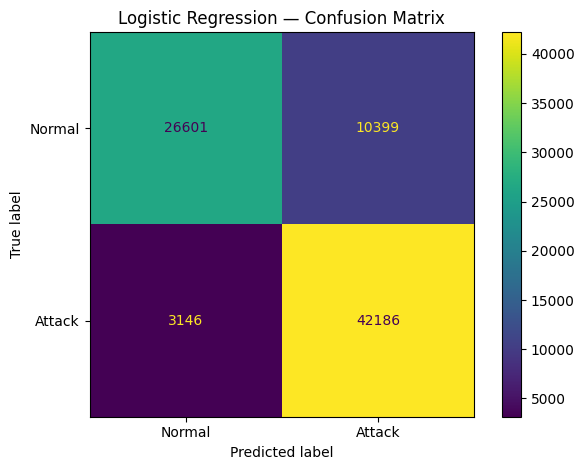

In [24]:
# ============================================================
# CELL 19 — CONFUSION MATRIX
# ============================================================

from sklearn.metrics import ConfusionMatrixDisplay

cm = confusion_matrix(
    y_test,
    logistic_predictions
)

print("=" * 80)
print("CONFUSION MATRIX")
print("=" * 80)

print(cm)

tn, fp, fn, tp = cm.ravel()

print("\nTrue Negatives  (Normal correctly detected):", tn)
print("False Positives (Normal wrongly flagged)   :", fp)
print("False Negatives (Attack missed)            :", fn)
print("True Positives   (Attack correctly detected):", tp)


ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=[
        "Normal",
        "Attack"
    ]
).plot(values_format="d")

plt.title(
    "Logistic Regression — Confusion Matrix"
)

plt.tight_layout()
plt.show()

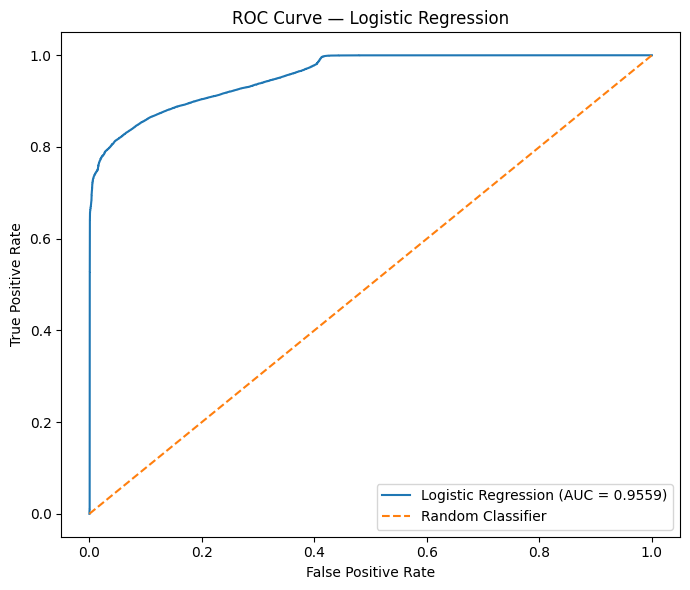

In [25]:
# ============================================================
# CELL 20 — ROC CURVE
# ============================================================

fpr, tpr, thresholds = roc_curve(
    y_test,
    logistic_probabilities
)

plt.figure(figsize=(7, 6))

plt.plot(
    fpr,
    tpr,
    label=f"Logistic Regression (AUC = {log_auc:.4f})"
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Random Classifier"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")

plt.title(
    "ROC Curve — Logistic Regression"
)

plt.legend()

plt.tight_layout()
plt.show()

In [26]:
# ============================================================
# CELL 21 — MODEL COMPARISON TABLE
# ============================================================

model_results = []

model_results.append({
    "Model": "Logistic Regression",
    "Accuracy": log_accuracy,
    "Precision": log_precision,
    "Recall": log_recall,
    "F1 Score": log_f1,
    "ROC-AUC": log_auc,
    "Training Time (s)": training_time
})

results_df = pd.DataFrame(model_results)

display(
    results_df.round(4)
)


,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC,Training Time (s)
0,Logistic Regression,0.8355,0.8022,0.9306,0.8617,0.9559,22.0068


In [27]:
# ============================================================
# CELL 22 — REUSABLE MODEL EVALUATION FUNCTION
# ============================================================

def evaluate_model(model_name, model, X_test, y_test, training_time):

    # Predictions
    predictions = model.predict(X_test)

    # Probabilities
    if hasattr(model, "predict_proba"):
        probabilities = model.predict_proba(X_test)[:, 1]
    else:
        probabilities = None

    # Metrics
    accuracy = accuracy_score(y_test, predictions)
    precision = precision_score(y_test, predictions)
    recall = recall_score(y_test, predictions)
    f1 = f1_score(y_test, predictions)

    if probabilities is not None:
        auc = roc_auc_score(y_test, probabilities)
    else:
        auc = np.nan

    # Confusion Matrix
    cm = confusion_matrix(y_test, predictions)

    tn, fp, fn, tp = cm.ravel()

    print("=" * 80)
    print(model_name.upper())
    print("=" * 80)

    print(f"\nAccuracy  : {accuracy:.4f} ({accuracy*100:.2f}%)")
    print(f"Precision : {precision:.4f} ({precision*100:.2f}%)")
    print(f"Recall    : {recall:.4f} ({recall*100:.2f}%)")
    print(f"F1 Score  : {f1:.4f} ({f1*100:.2f}%)")

    if probabilities is not None:
        print(f"ROC-AUC   : {auc:.4f}")

    print(f"\nTraining Time: {training_time:.2f} seconds")

    print("\nConfusion Matrix:")
    print(cm)

    print("\nTN:", tn)
    print("FP:", fp)
    print("FN:", fn)
    print("TP:", tp)

    print("\nClassification Report:\n")

    print(
        classification_report(
            y_test,
            predictions,
            target_names=["Normal", "Attack"],
            digits=4
        )
    )

    return {
        "Model": model_name,
        "Accuracy": accuracy,
        "Precision": precision,
        "Recall": recall,
        "F1 Score": f1,
        "ROC-AUC": auc,
        "Training Time (s)": training_time
    }

In [28]:
# ============================================================
# CELL 23 — MODEL 2: DECISION TREE
# ============================================================

print("=" * 80)
print("MODEL 2 — DECISION TREE")
print("=" * 80)

decision_tree_model = DecisionTreeClassifier(
    max_depth=20,
    min_samples_split=10,
    min_samples_leaf=5,
    class_weight="balanced",
    random_state=RANDOM_STATE
)

start_time = time.time()

print("\nTraining Decision Tree...")

decision_tree_model.fit(
    X_train_processed,
    y_train
)

dt_training_time = time.time() - start_time

print("\nDecision Tree training completed!")

print(
    f"Training time: {dt_training_time:.2f} seconds"
)

MODEL 2 — DECISION TREE

Training Decision Tree...

Decision Tree training completed!
Training time: 14.63 seconds


In [29]:
# ============================================================
# CELL 24 — EVALUATE DECISION TREE
# ============================================================

dt_result = evaluate_model(
    "Decision Tree",
    decision_tree_model,
    X_test_processed,
    y_test,
    dt_training_time
)

DECISION TREE

Accuracy  : 0.8937 (89.37%)
Precision : 0.8674 (86.74%)
Recall    : 0.9524 (95.24%)
F1 Score  : 0.9079 (90.79%)
ROC-AUC   : 0.9231

Training Time: 14.63 seconds

Confusion Matrix:
[[30400  6600]
 [ 2156 43176]]

TN: 30400
FP: 6600
FN: 2156
TP: 43176

Classification Report:

              precision    recall  f1-score   support

      Normal     0.9338    0.8216    0.8741     37000
      Attack     0.8674    0.9524    0.9079     45332

    accuracy                         0.8937     82332
   macro avg     0.9006    0.8870    0.8910     82332
weighted avg     0.8972    0.8937    0.8927     82332



In [30]:
# ============================================================
# CELL 25 — UPDATE MODEL COMPARISON
# ============================================================

model_results.append(dt_result)

results_df = pd.DataFrame(model_results)

display(
    results_df.round(4)
)

,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC,Training Time (s)
0,Logistic Regression,0.8355,0.8022,0.9306,0.8617,0.9559,22.0068
1,Decision Tree,0.8937,0.8674,0.9524,0.9079,0.9231,14.6294


             Network Record
                   ↓
        ┌──────────┼──────────┐
        ↓          ↓          ↓
      Tree 1     Tree 2     Tree 3 ... Tree N
        ↓          ↓          ↓
     Attack     Attack      Normal
        └──────────┬──────────┘
                   ↓
             Combined Vote
                   ↓
                ATTACK

In [31]:
# ============================================================
# CELL 26 — MODEL 3: RANDOM FOREST
# ============================================================

print("=" * 80)
print("MODEL 3 — RANDOM FOREST")
print("=" * 80)

random_forest_model = RandomForestClassifier(
    n_estimators=150,
    max_depth=25,
    min_samples_split=5,
    min_samples_leaf=2,
    class_weight="balanced",
    random_state=RANDOM_STATE,
    n_jobs=-1
)

start_time = time.time()

print("\nTraining Random Forest...")

random_forest_model.fit(
    X_train_processed,
    y_train
)

rf_training_time = time.time() - start_time

print("\nRandom Forest training completed!")

print(
    f"Training time: {rf_training_time:.2f} seconds"
)

MODEL 3 — RANDOM FOREST

Training Random Forest...

Random Forest training completed!
Training time: 262.79 seconds


In [32]:
# ============================================================
# CELL 27 — EVALUATE RANDOM FOREST
# ============================================================

rf_result = evaluate_model(
    "Random Forest",
    random_forest_model,
    X_test_processed,
    y_test,
    rf_training_time
)

RANDOM FOREST

Accuracy  : 0.8989 (89.89%)
Precision : 0.8597 (85.97%)
Recall    : 0.9756 (97.56%)
F1 Score  : 0.9140 (91.40%)
ROC-AUC   : 0.9843

Training Time: 262.79 seconds

Confusion Matrix:
[[29782  7218]
 [ 1107 44225]]

TN: 29782
FP: 7218
FN: 1107
TP: 44225

Classification Report:

              precision    recall  f1-score   support

      Normal     0.9642    0.8049    0.8774     37000
      Attack     0.8597    0.9756    0.9140     45332

    accuracy                         0.8989     82332
   macro avg     0.9119    0.8902    0.8957     82332
weighted avg     0.9066    0.8989    0.8975     82332



In [33]:
# ============================================================
# CELL 28 — UPDATE MODEL COMPARISON
# ============================================================

model_results.append(rf_result)

results_df = pd.DataFrame(model_results)

print("=" * 80)
print("MODEL COMPARISON — CURRENT RESULTS")
print("=" * 80)

display(
    results_df.round(4)
)

MODEL COMPARISON — CURRENT RESULTS


,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC,Training Time (s)
0,Logistic Regression,0.8355,0.8022,0.9306,0.8617,0.9559,22.0068
1,Decision Tree,0.8937,0.8674,0.9524,0.9079,0.9231,14.6294
2,Random Forest,0.8989,0.8597,0.9756,0.9140,0.9843,262.7926


In [34]:
# ============================================================
# CELL 29 — MODEL 4: XGBOOST
# ============================================================

print("=" * 80)
print("MODEL 4 — XGBOOST")
print("=" * 80)

# Calculate class balance ratio
normal_count = (y_train == 0).sum()
attack_count = (y_train == 1).sum()

scale_pos_weight = normal_count / attack_count

print("\nNormal training records:", normal_count)
print("Attack training records:", attack_count)
print("Scale pos weight:", round(scale_pos_weight, 4))


xgb_model = XGBClassifier(
    n_estimators=300,
    max_depth=8,
    learning_rate=0.08,
    subsample=0.8,
    colsample_bytree=0.8,
    objective="binary:logistic",
    eval_metric="logloss",
    random_state=RANDOM_STATE,
    n_jobs=-1
)

start_time = time.time()

print("\nTraining XGBoost...")

xgb_model.fit(
    X_train_processed,
    y_train
)

xgb_training_time = time.time() - start_time

print("\nXGBoost training completed!")

print(
    f"Training time: {xgb_training_time:.2f} seconds"
)

MODEL 4 — XGBOOST

Normal training records: 56000
Attack training records: 119341
Scale pos weight: 0.4692

Training XGBoost...

XGBoost training completed!
Training time: 14.35 seconds


In [35]:
# ============================================================
# CELL 30 — EVALUATE XGBOOST
# ============================================================

xgb_result = evaluate_model(
    "XGBoost",
    xgb_model,
    X_test_processed,
    y_test,
    xgb_training_time
)

XGBOOST

Accuracy  : 0.8728 (87.28%)
Precision : 0.8211 (82.11%)
Recall    : 0.9833 (98.33%)
F1 Score  : 0.8949 (89.49%)
ROC-AUC   : 0.9837

Training Time: 14.35 seconds

Confusion Matrix:
[[27286  9714]
 [  755 44577]]

TN: 27286
FP: 9714
FN: 755
TP: 44577

Classification Report:

              precision    recall  f1-score   support

      Normal     0.9731    0.7375    0.8390     37000
      Attack     0.8211    0.9833    0.8949     45332

    accuracy                         0.8728     82332
   macro avg     0.8971    0.8604    0.8670     82332
weighted avg     0.8894    0.8728    0.8698     82332



In [36]:
# ============================================================
# CELL 31 — UPDATE MODEL COMPARISON
# ============================================================

model_results.append(xgb_result)

results_df = pd.DataFrame(model_results)

print("=" * 80)
print("MODEL COMPARISON — 4 MODELS")
print("=" * 80)

display(
    results_df.round(4)
)

MODEL COMPARISON — 4 MODELS


,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC,Training Time (s)
0,Logistic Regression,0.8355,0.8022,0.9306,0.8617,0.9559,22.0068
1,Decision Tree,0.8937,0.8674,0.9524,0.9079,0.9231,14.6294
2,Random Forest,0.8989,0.8597,0.9756,0.9140,0.9843,262.7926
3,XGBoost,0.8728,0.8211,0.9833,0.8949,0.9837,14.3501


In [37]:
# ============================================================
# CELL 32 — PREPARE DATA FOR NEURAL NETWORK
# ============================================================

from scipy import sparse

print("=" * 80)
print("PREPARING DATA FOR NEURAL NETWORK")
print("=" * 80)

if sparse.issparse(X_train_processed):
    X_train_nn = X_train_processed.astype("float32").toarray()
    X_test_nn = X_test_processed.astype("float32").toarray()
else:
    X_train_nn = np.asarray(
        X_train_processed,
        dtype=np.float32
    )

    X_test_nn = np.asarray(
        X_test_processed,
        dtype=np.float32
    )

y_train_nn = np.asarray(y_train, dtype=np.float32)
y_test_nn = np.asarray(y_test, dtype=np.float32)

print("\nTraining shape:", X_train_nn.shape)
print("Testing shape :", X_test_nn.shape)

print("\nTraining dtype:", X_train_nn.dtype)

print(
    "\nApprox training memory:",
    round(X_train_nn.nbytes / (1024**2), 2),
    "MB"
)

print("Neural-network data ready!")

PREPARING DATA FOR NEURAL NETWORK

Training shape: (175341, 194)
Testing shape : (82332, 194)

Training dtype: float32

Approx training memory: 129.76 MB
Neural-network data ready!


In [38]:
# ============================================================
# CELL 33 — MODEL 5: DEEP NEURAL NETWORK
# ============================================================

print("=" * 80)
print("MODEL 5 — DEEP NEURAL NETWORK")
print("=" * 80)

tf.keras.backend.clear_session()

nn_model = keras.Sequential([

    layers.Input(shape=(X_train_nn.shape[1],)),

    layers.Dense(
        128,
        activation="relu"
    ),

    layers.BatchNormalization(),

    layers.Dropout(0.30),

    layers.Dense(
        64,
        activation="relu"
    ),

    layers.BatchNormalization(),

    layers.Dropout(0.20),

    layers.Dense(
        32,
        activation="relu"
    ),

    layers.Dense(
        1,
        activation="sigmoid"
    )
])


nn_model.compile(
    optimizer=keras.optimizers.Adam(
        learning_rate=0.001
    ),
    loss="binary_crossentropy",
    metrics=["accuracy"]
)


early_stopping = keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=3,
    restore_best_weights=True
)


print("\nNeural Network Architecture:")
nn_model.summary()


start_time = time.time()

history = nn_model.fit(
    X_train_nn,
    y_train_nn,

    validation_split=0.15,

    epochs=20,

    batch_size=512,

    callbacks=[early_stopping],

    verbose=1
)

nn_training_time = time.time() - start_time

print("\nNeural Network training completed!")

print(
    f"Training time: {nn_training_time:.2f} seconds"
)

MODEL 5 — DEEP NEURAL NETWORK

Neural Network Architecture:


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 128)            │        24,960 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 128)            │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 64)             │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 36,097 (141.00 KB)

 Trainable params: 35,713 (139.50 KB)

 Non-trainable params: 384 (1.50 KB)

Epoch 1/20
292/292 ━━━━━━━━━━━━━━━━━━━━ 11s 21ms/step - accuracy: 0.9092 - loss: 0.2068 - val_accuracy: 0.9961 - val_loss: 0.0366
Epoch 2/20
292/292 ━━━━━━━━━━━━━━━━━━━━ 5s 17ms/step - accuracy: 0.9266 - loss: 0.1492 - val_accuracy: 0.9938 - val_loss: 0.0322
Epoch 3/20
292/292 ━━━━━━━━━━━━━━━━━━━━ 3s 9ms/step - accuracy: 0.9286 - loss: 0.1431 - val_accuracy: 0.9936 - val_loss: 0.0323
Epoch 4/20
292/292 ━━━━━━━━━━━━━━━━━━━━ 3s 9ms/step - accuracy: 0.9289 - loss: 0.1403 - val_accuracy: 0.9930 - val_loss: 0.0291
Epoch 5/20
292/292 ━━━━━━━━━━━━━━━━━━━━ 7s 25ms/step - accuracy: 0.9308 - loss: 0.1377 - val_accuracy: 0.9904 - val_loss: 0.0315
Epoch 6/20
292/292 ━━━━━━━━━━━━━━━━━━━━ 6s 20ms/step - accuracy: 0.9312 - loss: 0.1371 - val_accuracy: 0.9903 - val_loss: 0.0342
Epoch 7/20
292/292 ━━━━━━━━━━━━━━━━━━━━ 8s 26ms/step - accuracy: 0.9323 - loss: 0.1347 - val_accuracy: 0.9906 - val_loss: 0.0285
Epoch 8/20
292/292 ━━━━━━━━━━━━━━━━━━━━ 8s 26ms/step - accuracy: 0.9334 - loss: 0.1332 - val_accur

In [39]:
# ============================================================
# CELL 34 — EVALUATE NEURAL NETWORK
# ============================================================

nn_probabilities = nn_model.predict(
    X_test_nn,
    batch_size=1024,
    verbose=0
).ravel()

nn_predictions = (
    nn_probabilities >= 0.5
).astype(int)


nn_accuracy = accuracy_score(
    y_test,
    nn_predictions
)

nn_precision = precision_score(
    y_test,
    nn_predictions
)

nn_recall = recall_score(
    y_test,
    nn_predictions
)

nn_f1 = f1_score(
    y_test,
    nn_predictions
)

nn_auc = roc_auc_score(
    y_test,
    nn_probabilities
)


print("=" * 80)
print("DEEP NEURAL NETWORK — TEST RESULTS")
print("=" * 80)

print(f"\nAccuracy  : {nn_accuracy:.4f} ({nn_accuracy*100:.2f}%)")
print(f"Precision : {nn_precision:.4f} ({nn_precision*100:.2f}%)")
print(f"Recall    : {nn_recall:.4f} ({nn_recall*100:.2f}%)")
print(f"F1 Score  : {nn_f1:.4f} ({nn_f1*100:.2f}%)")
print(f"ROC-AUC   : {nn_auc:.4f}")

cm_nn = confusion_matrix(
    y_test,
    nn_predictions
)

print("\nConfusion Matrix:")
print(cm_nn)


nn_result = {
    "Model": "Deep Neural Network",
    "Accuracy": nn_accuracy,
    "Precision": nn_precision,
    "Recall": nn_recall,
    "F1 Score": nn_f1,
    "ROC-AUC": nn_auc,
    "Training Time (s)": nn_training_time
}

model_results.append(nn_result)

DEEP NEURAL NETWORK — TEST RESULTS

Accuracy  : 0.8691 (86.91%)
Precision : 0.8144 (81.44%)
Recall    : 0.9872 (98.72%)
F1 Score  : 0.8925 (89.25%)
ROC-AUC   : 0.9806

Confusion Matrix:
[[26804 10196]
 [  582 44750]]


In [40]:
# ============================================================
# CELL 35 — COMPARE ALL 5 INDIVIDUAL MODELS
# ============================================================

results_df = pd.DataFrame(
    model_results
)

results_df = results_df.sort_values(
    by="F1 Score",
    ascending=False
).reset_index(drop=True)

print("=" * 80)
print("MODEL COMPARISON — 5 MODELS")
print("=" * 80)

display(
    results_df.round(4)
)

MODEL COMPARISON — 5 MODELS


,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC,Training Time (s)
0,Random Forest,0.8989,0.8597,0.9756,0.9140,0.9843,262.7926
1,Decision Tree,0.8937,0.8674,0.9524,0.9079,0.9231,14.6294
2,XGBoost,0.8728,0.8211,0.9833,0.8949,0.9837,14.3501
3,Deep Neural Network,0.8691,0.8144,0.9872,0.8925,0.9806,86.4819
4,Logistic Regression,0.8355,0.8022,0.9306,0.8617,0.9559,22.0068


In [41]:
# ============================================================
# CELL 36 — CREATE VALIDATION SET FOR ENSEMBLE
# ============================================================

from sklearn.model_selection import train_test_split

print("=" * 80)
print("CREATING ENSEMBLE VALIDATION SET")
print("=" * 80)

ensemble_indices = np.arange(len(y_train))

_, validation_indices = train_test_split(
    ensemble_indices,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=y_train
)

X_validation = X_train_processed[
    validation_indices
]

X_validation_nn = X_train_nn[
    validation_indices
]

y_validation = np.asarray(y_train)[
    validation_indices
]

print("\nValidation records:",
      len(y_validation))

print(
    "Normal:",
    np.sum(y_validation == 0)
)

print(
    "Attack:",
    np.sum(y_validation == 1)
)

CREATING ENSEMBLE VALIDATION SET

Validation records: 35069
Normal: 11200
Attack: 23869


Random Forest
      +
XGBoost
      +
Neural Network
      ↓
Weighted probability
      ↓
Final prediction

In [42]:
# ============================================================
# CELL 37 — PROPOSED HYBRID ENSEMBLE
# ============================================================

print("=" * 80)
print("PROPOSED HYBRID ENSEMBLE")
print("=" * 80)

# Get probabilities from the three models
rf_prob = random_forest_model.predict_proba(
    X_test_processed
)[:, 1]

xgb_prob = xgb_model.predict_proba(
    X_test_processed
)[:, 1]

# nn_probabilities already calculated in Cell 34


# ------------------------------------------------------------
# PRE-SPECIFIED WEIGHTS
# ------------------------------------------------------------

RF_WEIGHT = 0.50
XGB_WEIGHT = 0.25
NN_WEIGHT = 0.25


ensemble_probabilities = (
    RF_WEIGHT * rf_prob
    +
    XGB_WEIGHT * xgb_prob
    +
    NN_WEIGHT * nn_probabilities
)


ENSEMBLE_THRESHOLD = 0.50

ensemble_predictions = (
    ensemble_probabilities >= ENSEMBLE_THRESHOLD
).astype(int)


print("\nWeights:")

print("Random Forest :", RF_WEIGHT)
print("XGBoost       :", XGB_WEIGHT)
print("Neural Network:", NN_WEIGHT)

print("\nThreshold:", ENSEMBLE_THRESHOLD)

print("\nPredictions generated:",
      len(ensemble_predictions))

PROPOSED HYBRID ENSEMBLE

Weights:
Random Forest : 0.5
XGBoost       : 0.25
Neural Network: 0.25

Threshold: 0.5

Predictions generated: 82332


In [43]:
# ============================================================
# CELL 38 — EVALUATE PROPOSED ENSEMBLE
# ============================================================

ensemble_accuracy = accuracy_score(
    y_test,
    ensemble_predictions
)

ensemble_precision = precision_score(
    y_test,
    ensemble_predictions
)

ensemble_recall = recall_score(
    y_test,
    ensemble_predictions
)

ensemble_f1 = f1_score(
    y_test,
    ensemble_predictions
)

ensemble_auc = roc_auc_score(
    y_test,
    ensemble_probabilities
)


ensemble_cm = confusion_matrix(
    y_test,
    ensemble_predictions
)

tn, fp, fn, tp = ensemble_cm.ravel()


print("=" * 80)
print("PROPOSED HYBRID ENSEMBLE — RESULTS")
print("=" * 80)

print(
    f"\nAccuracy  : {ensemble_accuracy:.4f} "
    f"({ensemble_accuracy*100:.2f}%)"
)

print(
    f"Precision : {ensemble_precision:.4f} "
    f"({ensemble_precision*100:.2f}%)"
)

print(
    f"Recall    : {ensemble_recall:.4f} "
    f"({ensemble_recall*100:.2f}%)"
)

print(
    f"F1 Score  : {ensemble_f1:.4f} "
    f"({ensemble_f1*100:.2f}%)"
)

print(
    f"ROC-AUC   : {ensemble_auc:.4f}"
)


print("\nConfusion Matrix:")
print(ensemble_cm)

print("\nTN:", tn)
print("FP:", fp)
print("FN:", fn)
print("TP:", tp)

PROPOSED HYBRID ENSEMBLE — RESULTS

Accuracy  : 0.8872 (88.72%)
Precision : 0.8387 (83.87%)
Recall    : 0.9845 (98.45%)
F1 Score  : 0.9058 (90.58%)
ROC-AUC   : 0.9847

Confusion Matrix:
[[28417  8583]
 [  704 44628]]

TN: 28417
FP: 8583
FN: 704
TP: 44628


In [44]:
# ============================================================
# CELL 39 — ADD ENSEMBLE TO RESULTS
# ============================================================

ensemble_result = {
    "Model": "Proposed Hybrid Ensemble",
    "Accuracy": ensemble_accuracy,
    "Precision": ensemble_precision,
    "Recall": ensemble_recall,
    "F1 Score": ensemble_f1,
    "ROC-AUC": ensemble_auc,
    "Training Time (s)": np.nan
}

model_results.append(
    ensemble_result
)

final_results_df = pd.DataFrame(
    model_results
)

final_results_df = (
    final_results_df
    .drop_duplicates(
        subset=["Model"],
        keep="last"
    )
    .sort_values(
        "F1 Score",
        ascending=False
    )
    .reset_index(drop=True)
)

print("=" * 80)
print("FINAL BINARY MODEL COMPARISON")
print("=" * 80)

display(
    final_results_df.round(4)
)

FINAL BINARY MODEL COMPARISON


,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC,Training Time (s)
0,Random Forest,0.8989,0.8597,0.9756,0.9140,0.9843,262.7926
1,Decision Tree,0.8937,0.8674,0.9524,0.9079,0.9231,14.6294
2,Proposed Hybrid Ensemble,0.8872,0.8387,0.9845,0.9058,0.9847,NaN
3,XGBoost,0.8728,0.8211,0.9833,0.8949,0.9837,14.3501
4,Deep Neural Network,0.8691,0.8144,0.9872,0.8925,0.9806,86.4819
5,Logistic Regression,0.8355,0.8022,0.9306,0.8617,0.9559,22.0068


In [45]:
# ============================================================
# CELL 40 — PREPARE MULTICLASS ATTACK DATA
# ============================================================

print("=" * 80)
print("MULTICLASS ATTACK-TYPE CLASSIFICATION")
print("=" * 80)

attack_train_df = train_df[
    train_df["label"] == 1
].copy()

attack_test_df = test_df[
    test_df["label"] == 1
].copy()

print("\nAttack training records:",
      len(attack_train_df))

print("Attack testing records:",
      len(attack_test_df))

print("\nTraining attack categories:")
print(
    attack_train_df["attack_cat"]
    .value_counts()
)

print("\nTesting attack categories:")
print(
    attack_test_df["attack_cat"]
    .value_counts()
)

MULTICLASS ATTACK-TYPE CLASSIFICATION

Attack training records: 119341
Attack testing records: 45332

Training attack categories:
attack_cat
Generic           40000
Exploits          33393
Fuzzers           18184
DoS               12264
Reconnaissance    10491
Analysis           2000
Backdoor           1746
Shellcode          1133
Worms               130
Name: count, dtype: int64

Testing attack categories:
attack_cat
Generic           18871
Exploits          11132
Fuzzers            6062
DoS                4089
Reconnaissance     3496
Analysis            677
Backdoor            583
Shellcode           378
Worms                44
Name: count, dtype: int64


In [46]:
# ============================================================
# CELL 41 — MULTICLASS FEATURES AND TARGET
# ============================================================

MULTICLASS_TARGET = "attack_cat"

X_attack_train = attack_train_df.drop(
    columns=[
        "id",
        "label",
        "attack_cat"
    ]
)

y_attack_train = attack_train_df[
    MULTICLASS_TARGET
].copy()


X_attack_test = attack_test_df.drop(
    columns=[
        "id",
        "label",
        "attack_cat"
    ]
)

y_attack_test = attack_test_df[
    MULTICLASS_TARGET
].copy()


print("X attack train:",
      X_attack_train.shape)

print("y attack train:",
      y_attack_train.shape)

print("X attack test :",
      X_attack_test.shape)

print("y attack test :",
      y_attack_test.shape)

print(
    "\nNumber of attack classes:",
    y_attack_train.nunique()
)

X attack train: (119341, 42)
y attack train: (119341,)
X attack test : (45332, 42)
y attack test : (45332,)

Number of attack classes: 9


In [47]:
# ============================================================
# CELL 42 — MULTICLASS PREPROCESSING
# ============================================================

attack_categorical_features = (
    X_attack_train
    .select_dtypes(
        include=["object"]
    )
    .columns
    .tolist()
)

attack_numerical_features = [
    col
    for col in X_attack_train.columns
    if col not in attack_categorical_features
]


print("Categorical features:")
print(attack_categorical_features)

print(
    "\nNumerical features:",
    len(attack_numerical_features)
)


attack_numerical_pipeline = Pipeline(
    steps=[
        (
            "imputer",
            SimpleImputer(
                strategy="median"
            )
        ),

        (
            "scaler",
            StandardScaler()
        )
    ]
)


attack_categorical_pipeline = Pipeline(
    steps=[
        (
            "imputer",
            SimpleImputer(
                strategy="most_frequent"
            )
        ),

        (
            "onehot",
            OneHotEncoder(
                handle_unknown="ignore",
                sparse_output=True
            )
        )
    ]
)


attack_preprocessor = ColumnTransformer(
    transformers=[
        (
            "numerical",
            attack_numerical_pipeline,
            attack_numerical_features
        ),

        (
            "categorical",
            attack_categorical_pipeline,
            attack_categorical_features
        )
    ]
)


X_attack_train_processed = (
    attack_preprocessor.fit_transform(
        X_attack_train
    )
)

X_attack_test_processed = (
    attack_preprocessor.transform(
        X_attack_test
    )
)


print(
    "\nProcessed attack training shape:",
    X_attack_train_processed.shape
)

print(
    "Processed attack testing shape:",
    X_attack_test_processed.shape
)

Categorical features:
['proto', 'service', 'state']

Numerical features: 39

Processed attack training shape: (119341, 186)
Processed attack testing shape: (45332, 186)


In [48]:
# ============================================================
# CELL 43 — CALCULATE MULTICLASS SAMPLE WEIGHTS
# ============================================================

from sklearn.utils.class_weight import compute_sample_weight

attack_sample_weights = compute_sample_weight(
    class_weight="balanced",
    y=y_attack_train
)

print("=" * 80)
print("MULTICLASS CLASS-IMBALANCE HANDLING")
print("=" * 80)

print(
    "\nNumber of sample weights:",
    len(attack_sample_weights)
)

print(
    "Minimum weight:",
    round(
        attack_sample_weights.min(),
        4
    )
)

print(
    "Maximum weight:",
    round(
        attack_sample_weights.max(),
        4
    )
)

print(
    "\nClass balancing weights successfully created."
)

MULTICLASS CLASS-IMBALANCE HANDLING

Number of sample weights: 119341
Minimum weight: 0.3315
Maximum weight: 102.0009

Class balancing weights successfully created.


In [49]:
# ============================================================
# CELL 44 — ATTACK-TYPE RANDOM FOREST
# ============================================================

print("=" * 80)
print("TRAINING ATTACK-TYPE CLASSIFIER")
print("=" * 80)

attack_classifier = RandomForestClassifier(
    n_estimators=200,
    max_depth=25,
    min_samples_split=5,
    min_samples_leaf=2,
    random_state=RANDOM_STATE,
    n_jobs=-1
)

start_time = time.time()

attack_classifier.fit(
    X_attack_train_processed,
    y_attack_train,
    sample_weight=attack_sample_weights
)

attack_training_time = (
    time.time() - start_time
)

print(
    "\nAttack classifier training completed!"
)

print(
    f"Training time: "
    f"{attack_training_time:.2f} seconds"
)

TRAINING ATTACK-TYPE CLASSIFIER

Attack classifier training completed!
Training time: 443.40 seconds


In [50]:
# ============================================================
# CELL 45 — EVALUATE ATTACK-TYPE CLASSIFIER
# ============================================================

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)

attack_predictions = attack_classifier.predict(
    X_attack_test_processed
)


attack_accuracy = accuracy_score(
    y_attack_test,
    attack_predictions
)

attack_macro_precision = precision_score(
    y_attack_test,
    attack_predictions,
    average="macro",
    zero_division=0
)

attack_macro_recall = recall_score(
    y_attack_test,
    attack_predictions,
    average="macro",
    zero_division=0
)

attack_macro_f1 = f1_score(
    y_attack_test,
    attack_predictions,
    average="macro",
    zero_division=0
)

attack_weighted_f1 = f1_score(
    y_attack_test,
    attack_predictions,
    average="weighted",
    zero_division=0
)


print("=" * 80)
print("ATTACK-TYPE CLASSIFICATION RESULTS")
print("=" * 80)

print(
    f"\nAccuracy        : "
    f"{attack_accuracy:.4f} "
    f"({attack_accuracy*100:.2f}%)"
)

print(
    f"Macro Precision : "
    f"{attack_macro_precision:.4f}"
)

print(
    f"Macro Recall    : "
    f"{attack_macro_recall:.4f}"
)

print(
    f"Macro F1        : "
    f"{attack_macro_f1:.4f}"
)

print(
    f"Weighted F1     : "
    f"{attack_weighted_f1:.4f}"
)


print("\nClassification Report:\n")

print(
    classification_report(
        y_attack_test,
        attack_predictions,
        digits=4,
        zero_division=0
    )
)

ATTACK-TYPE CLASSIFICATION RESULTS

Accuracy        : 0.7549 (75.49%)
Macro Precision : 0.5339
Macro Recall    : 0.5635
Macro F1        : 0.5175
Weighted F1     : 0.7837

Classification Report:

                precision    recall  f1-score   support

      Analysis     0.0078    0.0030    0.0043       677
      Backdoor     0.0353    0.3225    0.0637       583
           DoS     0.3078    0.2152    0.2533      4089
      Exploits     0.8219    0.6362    0.7172     11132
       Fuzzers     0.8111    0.7616    0.7856      6062
       Generic     0.9997    0.9629    0.9810     18871
Reconnaissance     0.8764    0.8375    0.8565      3496
     Shellcode     0.3205    0.8783    0.4696       378
         Worms     0.6250    0.4545    0.5263        44

      accuracy                         0.7549     45332
     macro avg     0.5339    0.5635    0.5175     45332
  weighted avg     0.8257    0.7549    0.7837     45332



**ATTACK**

In [51]:
# ============================================================
# CELL 46 — PREPARE SHAP EXPLAINABLE AI
# ============================================================

print("=" * 80)
print("EXPLAINABLE AI — SHAP")
print("=" * 80)

# Get names of all transformed features
feature_names = preprocessor.get_feature_names_out()

print("\nNumber of transformed features:",
      len(feature_names))

print("\nCreating SHAP TreeExplainer...")

shap_explainer = shap.TreeExplainer(
    xgb_model
)

# Use a sample instead of the entire test dataset
# to keep SHAP computation fast in Colab.

SHAP_SAMPLE_SIZE = min(
    1000,
    X_test_processed.shape[0]
)

rng = np.random.default_rng(
    RANDOM_STATE
)

shap_indices = rng.choice(
    X_test_processed.shape[0],
    size=SHAP_SAMPLE_SIZE,
    replace=False
)

X_shap = X_test_processed[
    shap_indices
]

# Convert only this small sample to dense
if hasattr(X_shap, "toarray"):
    X_shap_dense = X_shap.toarray()
else:
    X_shap_dense = np.asarray(X_shap)

print(
    "SHAP sample shape:",
    X_shap_dense.shape
)

print("\nSHAP preparation completed!")

EXPLAINABLE AI — SHAP

Number of transformed features: 194

Creating SHAP TreeExplainer...
SHAP sample shape: (1000, 194)

SHAP preparation completed!


In [52]:
# ============================================================
# CELL 47 — CALCULATE SHAP VALUES
# ============================================================

print("=" * 80)
print("CALCULATING SHAP VALUES")
print("=" * 80)

shap_values = shap_explainer(
    X_shap_dense
)

print("\nSHAP values calculated!")

print(
    "SHAP value shape:",
    shap_values.values.shape
)

CALCULATING SHAP VALUES

SHAP values calculated!
SHAP value shape: (1000, 194)


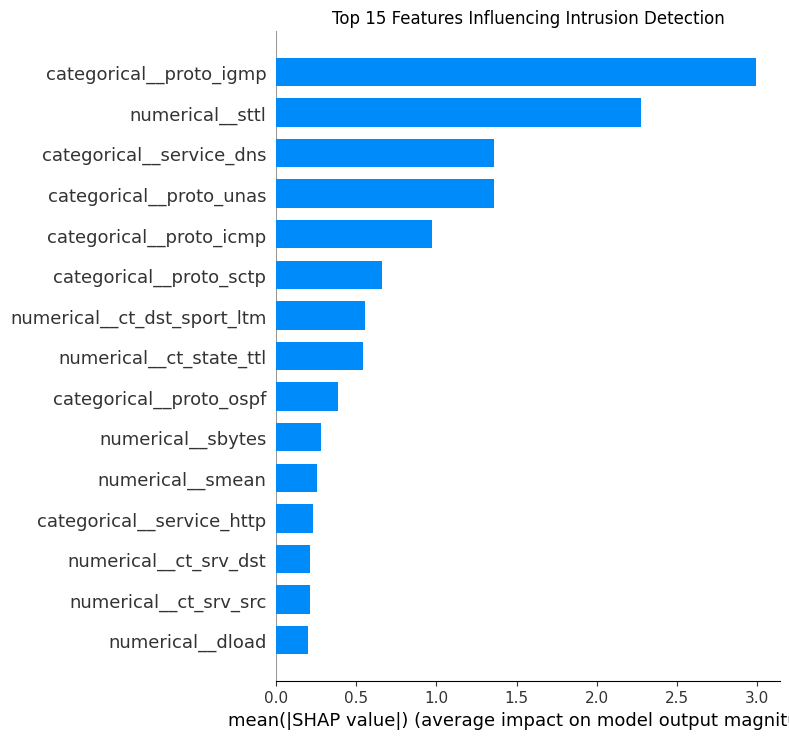

In [53]:
# ============================================================
# CELL 48 — SHAP GLOBAL FEATURE IMPORTANCE
# ============================================================

plt.figure(figsize=(10, 8))

shap.summary_plot(
    shap_values.values,
    X_shap_dense,
    feature_names=feature_names,
    plot_type="bar",
    max_display=15,
    show=False
)

plt.title(
    "Top 15 Features Influencing Intrusion Detection"
)

plt.tight_layout()
plt.show()

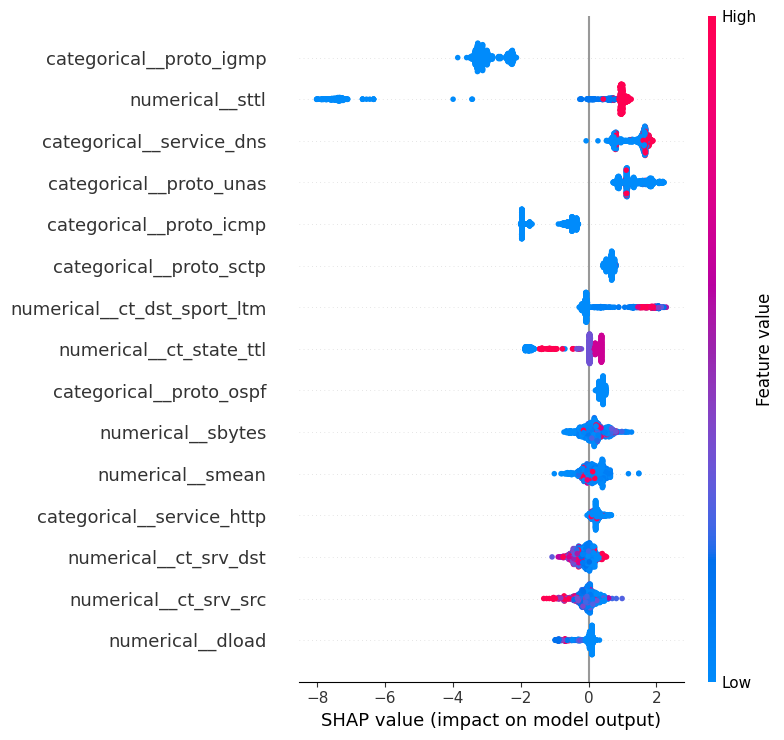

In [54]:
# ============================================================
# CELL 49 — DETAILED SHAP SUMMARY
# ============================================================

shap.summary_plot(
    shap_values.values,
    X_shap_dense,
    feature_names=feature_names,
    max_display=15
)

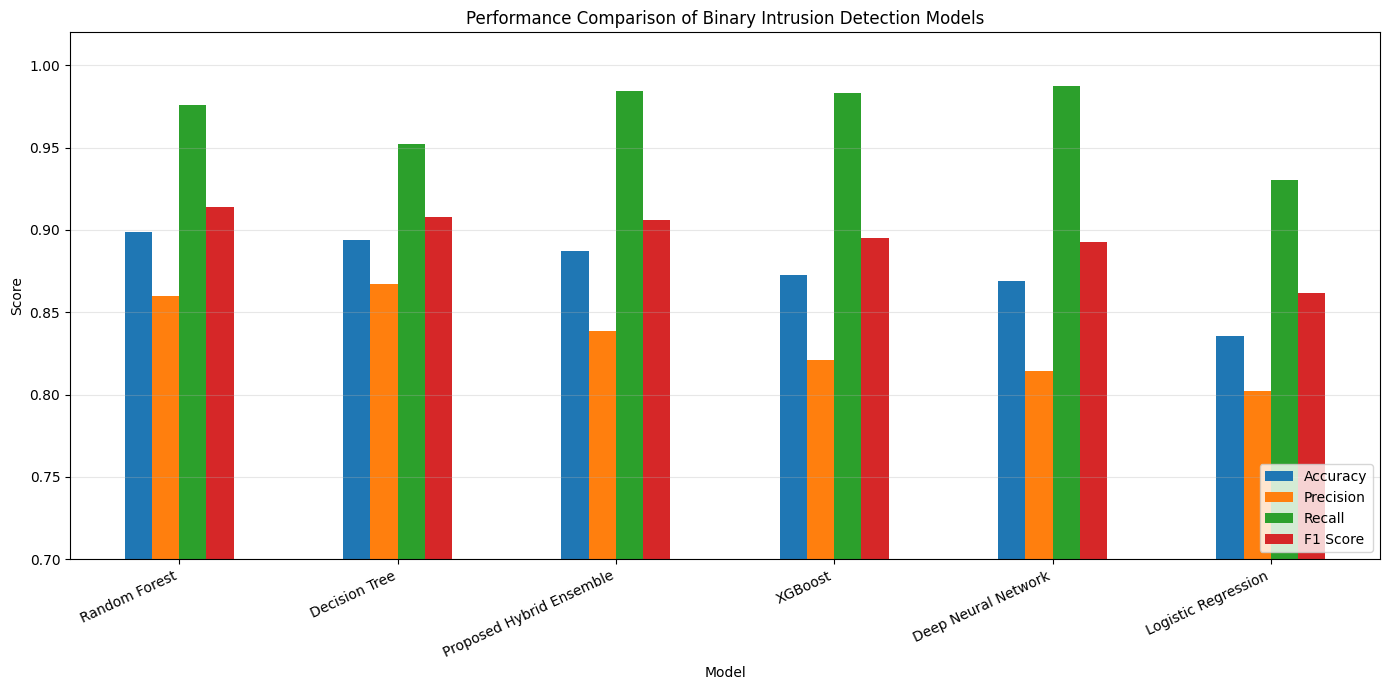

In [55]:
# ============================================================
# CELL 50 — FINAL MODEL PERFORMANCE GRAPH
# ============================================================

comparison_plot = final_results_df[
    ["Model", "Accuracy", "Precision", "Recall", "F1 Score"]
].copy()

comparison_plot = comparison_plot.set_index("Model")

ax = comparison_plot.plot(
    kind="bar",
    figsize=(14, 7)
)

plt.title(
    "Performance Comparison of Binary Intrusion Detection Models"
)

plt.ylabel("Score")
plt.xlabel("Model")

plt.ylim(0.70, 1.02)

plt.xticks(
    rotation=25,
    ha="right"
)

plt.legend(
    loc="lower right"
)

plt.grid(
    axis="y",
    alpha=0.3
)

plt.tight_layout()
plt.show()

In [56]:
# ============================================================
# CELL 51 — SAVE TRAINED SYSTEM
# ============================================================

import os
import joblib

SAVE_DIR = "/content/intrusion_detection_system"

os.makedirs(
    SAVE_DIR,
    exist_ok=True
)

print("=" * 80)
print("SAVING TRAINED SYSTEM")
print("=" * 80)


# Binary preprocessing
joblib.dump(
    preprocessor,
    f"{SAVE_DIR}/binary_preprocessor.pkl"
)


# Random Forest
joblib.dump(
    random_forest_model,
    f"{SAVE_DIR}/random_forest_model.pkl"
)


# XGBoost
xgb_model.save_model(
    f"{SAVE_DIR}/xgboost_model.json"
)


# Neural Network
nn_model.save(
    f"{SAVE_DIR}/neural_network.keras"
)


# Attack-type preprocessing
joblib.dump(
    attack_preprocessor,
    f"{SAVE_DIR}/attack_preprocessor.pkl"
)


# Attack-type classifier
joblib.dump(
    attack_classifier,
    f"{SAVE_DIR}/attack_classifier.pkl"
)


# Save expected raw feature names
joblib.dump(
    list(X_train_raw.columns),
    f"{SAVE_DIR}/required_features.pkl"
)


print("\nAll important components saved!")

print("\nSaved files:")

for filename in os.listdir(SAVE_DIR):
    print(" -", filename)

SAVING TRAINED SYSTEM

All important components saved!

Saved files:
 - attack_preprocessor.pkl
 - attack_classifier.pkl
 - neural_network.keras
 - random_forest_model.pkl
 - xgboost_model.json
 - binary_preprocessor.pkl
 - required_features.pkl


Dynamic Prediction Function            

new_network_data.csv
        ↓
Validate columns
        ↓
Saved preprocessing
        ↓
Binary intrusion detection
        ↓
Normal / Attack
        ↓
Attack type
        ↓
Probability
        ↓
Output CSV

In [57]:
# ============================================================
# CELL 52 — DYNAMIC INTRUSION PREDICTION FUNCTION
# ============================================================

def predict_network_data(new_df):

    data = new_df.copy()

    # --------------------------------------------------------
    # 1. Check required input features
    # --------------------------------------------------------

    required_features = list(
        X_train_raw.columns
    )

    missing_features = [
        col
        for col in required_features
        if col not in data.columns
    ]

    if missing_features:
        raise ValueError(
            "Missing required features:\n"
            + str(missing_features)
        )


    # --------------------------------------------------------
    # 2. Keep features in correct training order
    # --------------------------------------------------------

    model_input = data[
        required_features
    ].copy()


    # --------------------------------------------------------
    # 3. Binary preprocessing
    # --------------------------------------------------------

    processed_input = preprocessor.transform(
        model_input
    )


    # --------------------------------------------------------
    # 4. Binary prediction
    #
    # Random Forest is used as primary detector because
    # it achieved the strongest F1 score in our experiments.
    # --------------------------------------------------------

    attack_probability = (
        random_forest_model
        .predict_proba(processed_input)[:, 1]
    )

    binary_prediction = (
        attack_probability >= 0.50
    ).astype(int)


    # --------------------------------------------------------
    # 5. Create results
    # --------------------------------------------------------

    results = data.copy()

    results[
        "Predicted_Label"
    ] = binary_prediction

    results[
        "Prediction"
    ] = np.where(
        binary_prediction == 1,
        "Attack",
        "Normal"
    )

    results[
        "Attack_Probability"
    ] = attack_probability


    # --------------------------------------------------------
    # 6. Default attack type
    # --------------------------------------------------------

    results[
        "Predicted_Attack_Type"
    ] = "Normal"


    # --------------------------------------------------------
    # 7. Attack category prediction
    # --------------------------------------------------------

    attack_mask = (
        binary_prediction == 1
    )

    if attack_mask.any():

        attack_rows = model_input.loc[
            attack_mask
        ]

        attack_processed = (
            attack_preprocessor.transform(
                attack_rows
            )
        )

        attack_types = (
            attack_classifier.predict(
                attack_processed
            )
        )

        results.loc[
            attack_mask,
            "Predicted_Attack_Type"
        ] = attack_types


    # --------------------------------------------------------
    # 8. Prototype model-risk level
    # --------------------------------------------------------

    def get_risk(probability):

        if probability < 0.50:
            return "Low"

        elif probability < 0.70:
            return "Medium"

        elif probability < 0.90:
            return "High"

        else:
            return "Critical"


    results[
        "Model_Risk_Level"
    ] = results[
        "Attack_Probability"
    ].apply(get_risk)


    return results

In [58]:
# ============================================================
# CELL 53 — TEST DYNAMIC PREDICTION SYSTEM
# ============================================================

demo_data = test_df.sample(
    20,
    random_state=RANDOM_STATE
).copy()


demo_results = predict_network_data(
    demo_data
)


display_columns = [
    "Prediction",
    "Attack_Probability",
    "Predicted_Attack_Type",
    "Model_Risk_Level"
]


# Add actual values only for evaluation/demo
if "label" in demo_data.columns:

    demo_results[
        "Actual_Label"
    ] = demo_data[
        "label"
    ].values

    display_columns.append(
        "Actual_Label"
    )


if "attack_cat" in demo_data.columns:

    demo_results[
        "Actual_Attack_Type"
    ] = demo_data[
        "attack_cat"
    ].values

    display_columns.append(
        "Actual_Attack_Type"
    )


print("=" * 80)
print("DYNAMIC SYSTEM TEST — 20 NETWORK RECORDS")
print("=" * 80)

display(
    demo_results[
        display_columns
    ]
)

DYNAMIC SYSTEM TEST — 20 NETWORK RECORDS


,Prediction,Attack_Probability,Predicted_Attack_Type,Model_Risk_Level,Actual_Label,Actual_Attack_Type
38666,Normal,0.000003,Normal,Low,0,Normal
56460,Attack,0.999663,Generic,Critical,1,Generic
16266,Attack,0.996234,Generic,Critical,1,Generic
75603,Normal,0.001141,Normal,Low,0,Normal
11200,Attack,0.982406,Exploits,Critical,1,Exploits
21824,Attack,0.999791,Generic,Critical,1,Generic
28685,Normal,0.000000,Normal,Low,0,Normal
65457,Attack,0.969432,Exploits,Critical,1,Exploits
78819,Attack,0.821873,Fuzzers,High,0,Normal
8317,Attack,1.000000,Backdoor,Critical,1,Exploits


In [59]:
# ============================================================
# CELL 54 — CREATE SAMPLE DYNAMIC CSV
# ============================================================

sample_upload = test_df.sample(
    100,
    random_state=123
).copy()

# Simulate genuinely unseen data:
# remove target/output columns
sample_upload = sample_upload.drop(
    columns=[
        "id",
        "label",
        "attack_cat"
    ],
    errors="ignore"
)

sample_path = (
    "/content/sample_network_upload.csv"
)

sample_upload.to_csv(
    sample_path,
    index=False
)

print(
    "Sample dynamic CSV created:"
)

print(sample_path)

print(
    "\nShape:",
    sample_upload.shape
)

display(
    sample_upload.head()
)

Sample dynamic CSV created:
/content/sample_network_upload.csv

Shape: (100, 42)


,dur,proto,service,state,spkts,dpkts,sbytes,dbytes,rate,sttl,...,ct_dst_ltm,ct_src_dport_ltm,ct_dst_sport_ltm,ct_dst_src_ltm,is_ftp_login,ct_ftp_cmd,ct_flw_http_mthd,ct_src_ltm,ct_srv_dst,is_sm_ips_ports
50817,0.000001,udp,dns,INT,2,0,114,0,1.000000e+06,254,...,3,3,3,3,0,0,0,3,3,0
12742,0.000010,udp,dns,INT,2,0,114,0,1.000000e+05,254,...,12,12,12,12,0,0,0,12,12,0
54611,0.000005,udp,dns,INT,2,0,114,0,2.000000e+05,254,...,7,7,4,7,0,0,0,7,17,0
66902,0.000009,udp,-,INT,2,0,104,0,1.111111e+05,254,...,1,1,1,2,0,0,0,1,3,0
57368,0.000008,udp,dns,INT,2,0,114,0,1.250000e+05,254,...,2,2,2,2,0,0,0,2,12,0


In [61]:
# ============================================================
# CELL 55 — UPLOAD NEW CSV AND PREDICT
# ============================================================

from google.colab import files

print("=" * 80)
print("DYNAMIC NETWORK INTRUSION DETECTION")
print("=" * 80)

print("\nUpload a CSV containing network features.")

uploaded = files.upload()

uploaded_filename = next(
    iter(uploaded)
)

print(
    "\nUploaded:",
    uploaded_filename
)


new_network_df = pd.read_csv(
    uploaded_filename
)

print(
    "Records:",
    len(new_network_df)
)


dynamic_results = predict_network_data(
    new_network_df
)


output_file = (
    "/content/intrusion_detection_results.csv"
)

dynamic_results.to_csv(
    output_file,
    index=False
)


print("\nPrediction completed!")

print("\nSummary:")

print(
    dynamic_results[
        "Prediction"
    ].value_counts()
)

print("\nDetected attack types:")

print(
    dynamic_results.loc[
        dynamic_results["Prediction"] == "Attack",
        "Predicted_Attack_Type"
    ].value_counts()
)


display(
    dynamic_results[
        [
            "Prediction",
            "Attack_Probability",
            "Predicted_Attack_Type",
            "Model_Risk_Level"
        ]
    ].head(20)
)


files.download(
    output_file
)

DYNAMIC NETWORK INTRUSION DETECTION

Upload a CSV containing network features.


Saving sample_network_upload.csv to sample_network_upload (1).csv

Uploaded: sample_network_upload (1).csv
Records: 100

Prediction completed!

Summary:
Prediction
Attack    61
Normal    39
Name: count, dtype: int64

Detected attack types:
Predicted_Attack_Type
Generic           27
Exploits          12
Fuzzers           11
Reconnaissance     4
Backdoor           3
DoS                2
Shellcode          1
Analysis           1
Name: count, dtype: int64


,Prediction,Attack_Probability,Predicted_Attack_Type,Model_Risk_Level
0,Attack,0.952909,Generic,Critical
1,Attack,0.998657,Generic,Critical
2,Attack,0.995264,Generic,Critical
3,Attack,0.746555,Fuzzers,High
4,Attack,0.974859,Generic,Critical
5,Normal,0.094547,Normal,Low
6,Normal,0.369603,Normal,Low
7,Attack,0.993108,Generic,Critical
8,Attack,0.834744,Fuzzers,High
9,Attack,0.915380,Reconnaissance,Critical


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [62]:
# ============================================================
# CELL 56 — INSTALL GRADIO
# ============================================================

!pip -q install gradio

import gradio as gr

print("Gradio version:", gr.__version__)
print("Dashboard environment ready!")

Gradio version: 6.30.0
Dashboard environment ready!


In [63]:
# ============================================================
# CELL 57 — DASHBOARD BACKEND
# ============================================================

def dashboard_predict(file_path):

    if file_path is None:
        return (
            "Please upload a CSV file.",
            None,
            None
        )

    try:

        # Read uploaded CSV
        input_df = pd.read_csv(file_path)

        # Run our dynamic IDS
        results = predict_network_data(
            input_df
        )

        # Count predictions
        total_records = len(results)

        attack_count = (
            results["Prediction"]
            .eq("Attack")
            .sum()
        )

        normal_count = (
            results["Prediction"]
            .eq("Normal")
            .sum()
        )

        attack_percentage = (
            attack_count / total_records * 100
            if total_records > 0
            else 0
        )

        # Attack type summary
        attack_summary = (
            results.loc[
                results["Prediction"] == "Attack",
                "Predicted_Attack_Type"
            ]
            .value_counts()
        )

        # Create textual summary
        summary = f"""
INTRUSION DETECTION ANALYSIS

Total Network Records: {total_records}

Normal Records: {normal_count}

Attack Records: {attack_count}

Detected Attack Percentage: {attack_percentage:.2f}%

Attack Types:
{attack_summary.to_string()}
"""

        # Save downloadable result
        dashboard_output = (
            "/content/dashboard_intrusion_results.csv"
        )

        results.to_csv(
            dashboard_output,
            index=False
        )

        # Only display useful output columns
        preview = results[
            [
                "Prediction",
                "Attack_Probability",
                "Predicted_Attack_Type",
                "Model_Risk_Level"
            ]
        ].copy()

        return (
            summary,
            preview,
            dashboard_output
        )

    except Exception as e:

        return (
            f"ERROR:\n{str(e)}",
            None,
            None
        )


print(
    "Dashboard prediction function created successfully!"
)

Dashboard prediction function created successfully!


In [64]:
# ============================================================
# CELL 58 — CREATE INTERACTIVE IDS DASHBOARD
# ============================================================

with gr.Blocks(
    title="Explainable AI Network Intrusion Detection System"
) as demo:

    gr.Markdown(
        """
# 🛡️ Intelligent Network Intrusion Detection System

### Explainable Hybrid Machine Learning and Deep Learning Framework

Upload network traffic data in CSV format.

The system will automatically:

- Detect **Normal or Attack traffic**
- Calculate **attack probability**
- Identify the **predicted attack category**
- Assign a **model-risk level**
- Generate downloadable prediction results

---
"""
    )

    file_input = gr.File(
        label="Upload Network Traffic CSV",
        file_types=[".csv"],
        type="filepath"
    )

    analyze_button = gr.Button(
        "Analyze Network Traffic",
        variant="primary"
    )

    summary_output = gr.Textbox(
        label="Security Analysis Summary",
        lines=15
    )

    results_output = gr.Dataframe(
        label="Network Traffic Predictions",
        interactive=False
    )

    download_output = gr.File(
        label="Download Complete Prediction Results"
    )

    analyze_button.click(
        fn=dashboard_predict,
        inputs=file_input,
        outputs=[
            summary_output,
            results_output,
            download_output
        ]
    )


print("Dashboard created successfully!")

Dashboard created successfully!


In [65]:
# ============================================================
# CELL 59 — LAUNCH DASHBOARD
# ============================================================

demo.launch(
    share=True,
    debug=False
)

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://6fd68174cc41adc012.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


In [66]:
# ============================================================
# CELL 60 — FINAL PROJECT VERIFICATION
# ============================================================

print("=" * 80)
print("FINAL PROJECT SYSTEM CHECK")
print("=" * 80)

checks = {
    "Dataset loaded":
        "train_df" in globals(),

    "Binary preprocessing":
        "preprocessor" in globals(),

    "Logistic Regression":
        "logistic_model" in globals(),

    "Decision Tree":
        "decision_tree_model" in globals(),

    "Random Forest":
        "random_forest_model" in globals(),

    "XGBoost":
        "xgb_model" in globals(),

    "Deep Neural Network":
        "nn_model" in globals(),

    "Hybrid Ensemble":
        "ensemble_predictions" in globals(),

    "Attack-Type Classifier":
        "attack_classifier" in globals(),

    "SHAP Explainability":
        "shap_values" in globals(),

    "Dynamic Prediction Function":
        "predict_network_data" in globals(),

    "Dashboard":
        "demo" in globals()
}


for component, status in checks.items():

    symbol = "PASS" if status else "FAIL"

    print(
        f"{component:<32} : {symbol}"
    )


passed = sum(checks.values())
total = len(checks)

print("\n" + "=" * 80)

print(
    f"SYSTEM STATUS: {passed}/{total} components operational"
)

if passed == total:

    print(
        "\nPROJECT IMPLEMENTATION COMPLETED SUCCESSFULLY!"
    )

else:

    print(
        "\nSome components require attention."
    )

print("=" * 80)

FINAL PROJECT SYSTEM CHECK
Dataset loaded                   : PASS
Binary preprocessing             : PASS
Logistic Regression              : PASS
Decision Tree                    : PASS
Random Forest                    : PASS
XGBoost                          : PASS
Deep Neural Network              : PASS
Hybrid Ensemble                  : PASS
Attack-Type Classifier           : PASS
SHAP Explainability              : PASS
Dynamic Prediction Function      : PASS
Dashboard                        : PASS

SYSTEM STATUS: 12/12 components operational

PROJECT IMPLEMENTATION COMPLETED SUCCESSFULLY!
